In [1]:
#install all the required dependancy libraries
#!pip install tensorflow #for prediction
#!pip install numpy  #for matrix multiplication
#!pip install pandas #define the data structures
#!pip install matplotlib #for visualization
#!pip install scikit-learn #for normalizing our data(scaling)

#importing the libraries
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
import io
%matplotlib inline


In [4]:
#loading the dataset (Colab):
#from google.colab import files
#uploaded = files.upload()
#btc = pd.read_csv(io.StringIO(uploaded['data-bitcoin_timedata_v2.csv'].decode('utf-8')))

btc = pd.read_csv(r"C:\Users\caiof\Documents\Meus\_Estudos_\Faculdade\UFPE\2025.2\IF702 - REDES NEURAIS\Projetos\Mini projeto 2\data-bitcoin_timedata_v2.csv")

btc.head()

Por favor, faça o upload do seu arquivo 'data-bitcoin_timedata_v2.csv':


NameError: name 'files' is not defined

In [ ]:
# Hyperparametros:
train_size = 0.8
window_size = 7
batch_size = 7
learning_rate = 0.001
epochs = 100
units = 1
dropout_rate = 0.0

In [ ]:
#selecting only the column that we are going to use in the prediction process
data_to_use=btc['close'].values
data_to_use

array([ 4285.08,  4108.37,  4139.98, ..., 29281.09, 29232.25, 28902.49],
      shape=(2176,))

In [ ]:
# Definindo separação de dados:
separate_data = round(len(data_to_use)*train_size)
print("Total:", len(data_to_use))
print("80%:", separate_data)
print("20%:", len(data_to_use) - separate_data)

Total: 2176
80%: 1741
20%: 435


In [ ]:
# Separando dados de treino e teste:
train_data = data_to_use[:separate_data]
test_data = data_to_use[separate_data:]
print("Total data:", len(data_to_use))
print("Train data:", len(train_data))
print("Test data:", len(test_data))

Total data: 2176
Train data: 1741
Test data: 435


In [ ]:
#Normalizando dados:
scaler = MinMaxScaler(feature_range=(-1, 1))
scaler.fit(train_data.reshape(-1, 1))

train_data_normalized = scaler.transform(train_data.reshape(-1, 1))
test_data_normalized = scaler.transform(test_data.reshape(-1, 1))


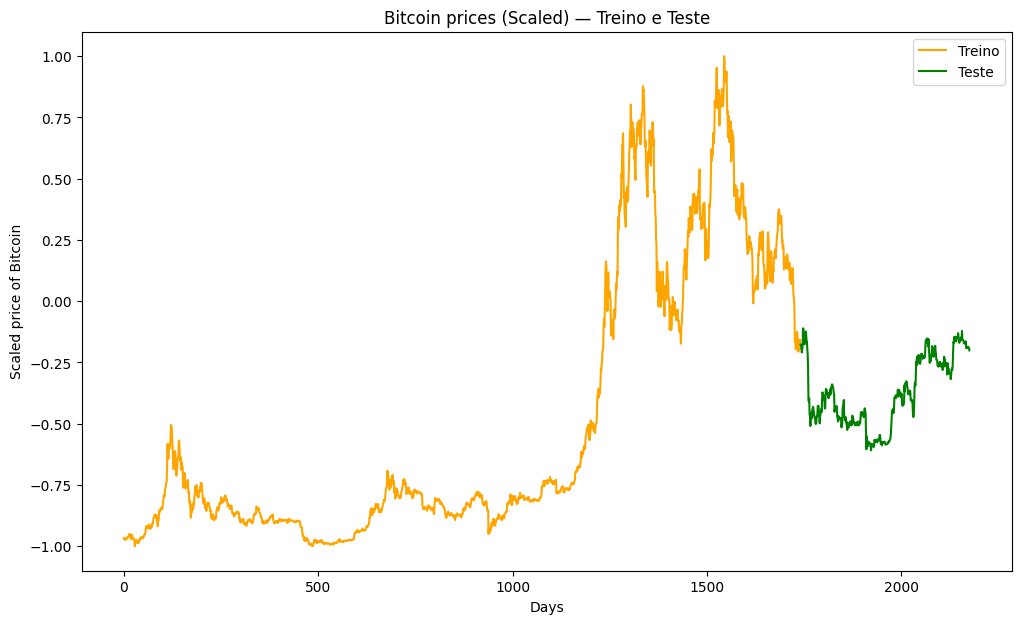

In [ ]:
# Plotando dados:
plt.figure(figsize=(12,7), frameon=False, facecolor='brown', edgecolor='blue')
plt.title('Bitcoin prices (Scaled) — Treino e Teste')
plt.xlabel('Days')
plt.ylabel('Scaled price of Bitcoin')
plt.plot(range(len(train_data_normalized)), train_data_normalized, label='Treino', color='orange')
plt.plot(range(len(train_data_normalized), len(train_data_normalized) + len(test_data_normalized)), test_data_normalized, label='Teste', color='green')
plt.legend()
plt.show()

In [ ]:
# This function is used to create Features and Labels datasets. By windowing the data.
#Input: data - dataset used in the project
#window_size - how many data points we are going to use to predict the next datapoint in the sequence
#[Example: if window_size = 1 we are going to use only the previous day to predict todays stock prices]
#Outputs: X - features splitted into windows of datapoints (if window_size = 1, X = [len(data)-1, 1])
#y - 'labels', actually this is the next number in the sequence, this number we are trying to predict

def window_data(data, window_size):
    X = []
    y = []

    i = 0
    while (i + window_size) <= len(data) - 1:
        X.append(data[i:i+window_size])
        y.append(data[i+window_size])

        i += 1
    assert len(X) ==  len(y)
    return np.array(X), np.array(y)

#windowing the data with window_data function
X_train, y_train = window_data(train_data_normalized, window_size)
X_test, y_test = window_data(test_data_normalized, window_size)

print("X_train size: {}".format(X_train.shape))
print("y_train size: {}".format(y_train.shape))
print("X_test size: {}".format(X_test.shape))
print("y_test size: {}".format(y_test.shape))

X_train size: (1734, 7, 1)
y_train size: (1734, 1)
X_test size: (428, 7, 1)
y_test size: (428, 1)


In [ ]:
# MODELO:
model = Sequential([
    LSTM(
        units=1,
        input_shape=(window_size, 1),
        activation='tanh',
        dropout=dropout_rate,
        recurrent_dropout=dropout_rate,
        return_sequences=False
    )
])

optimizer = Adam(learning_rate=learning_rate)

model.compile(optimizer='adam', loss='mse', metrics=['mae'])
model.summary()

c:\Users\caiof\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 1)              │            12 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12 (48.00 B)

 Trainable params: 12 (48.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# TREINANDO MODELO:
es = EarlyStopping(monitor='loss', patience=10, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=epochs,
    batch_size=batch_size,
    callbacks=[es],
    shuffle=False,  # mantém a ordem temporal
    verbose=1
)

Epoch 1/100
248/248 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.7203 - mae: 0.7854 - val_loss: 0.1358 - val_mae: 0.3357
Epoch 2/100
248/248 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4843 - mae: 0.6540 - val_loss: 0.0544 - val_mae: 0.1970
Epoch 3/100
248/248 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2425 - mae: 0.4527 - val_loss: 0.0086 - val_mae: 0.0786
Epoch 4/100
248/248 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.1206 - mae: 0.2820 - val_loss: 0.0128 - val_mae: 0.0915
Epoch 5/100
248/248 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0942 - mae: 0.2257 - val_loss: 0.0129 - val_mae: 0.0970
Epoch 6/100
248/248 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0810 - mae: 0.1983 - val_loss: 0.0106 - val_mae: 0.0904
Epoch 7/100
248/248 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0718 - mae: 0.1793 - val_loss: 0.0078 - val_mae: 0.0784
Epoch 8/100
248/248 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0649 - mae: 0.1642 - val_loss: 0.0051 - val_mae: 0.0636
Epoch 9/100
248/248 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/

In [ ]:
# TRAIN PREDICTIONS:
train_predictions = model.predict(X_train)
print("Predictions shape:", train_predictions.shape)

# Converter o tensor para numpy antes de transformar em lista
train_predictions_list = train_predictions.flatten().tolist()

# Converte para valores reais
train_predictions_real = scaler.inverse_transform(np.array(train_predictions_list).reshape(-1, 1)).flatten().tolist()

55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Predictions shape: (1734, 1)


In [ ]:
# TEST PREDICTIONS:
test_predictions = model.predict(X_test)
print("Predictions shape:", test_predictions.shape)

# Converter o tensor para numpy antes de transformar em lista
test_predictions_list = test_predictions.flatten().tolist()

# Converte para valores reais
test_predictions_real = scaler.inverse_transform(np.array(test_predictions_list).reshape(-1, 1)).flatten().tolist()

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
Predictions shape: (428, 1)


In [ ]:
# AJUSTE DOS RESULTADOS PARA PLOTAR (valores normalizados):
# Total de amostras: treino + teste
total_length = len(train_predictions_list + test_predictions_list)

# Lista final de resultados contínuos (None onde não há previsão)
train_results = []
test_results = []
for i in range(total_length):
    if i < len(train_predictions_list):
        train_results.append(train_predictions_list[i])
        test_results.append(None)
    else:
      train_results.append(None)
      test_index = i - len(train_predictions_list)
      test_results.append(test_predictions_list[test_index])

# Normaliza dados originais:
data_to_use_normalized = scaler.transform(data_to_use.reshape(-1, 1))

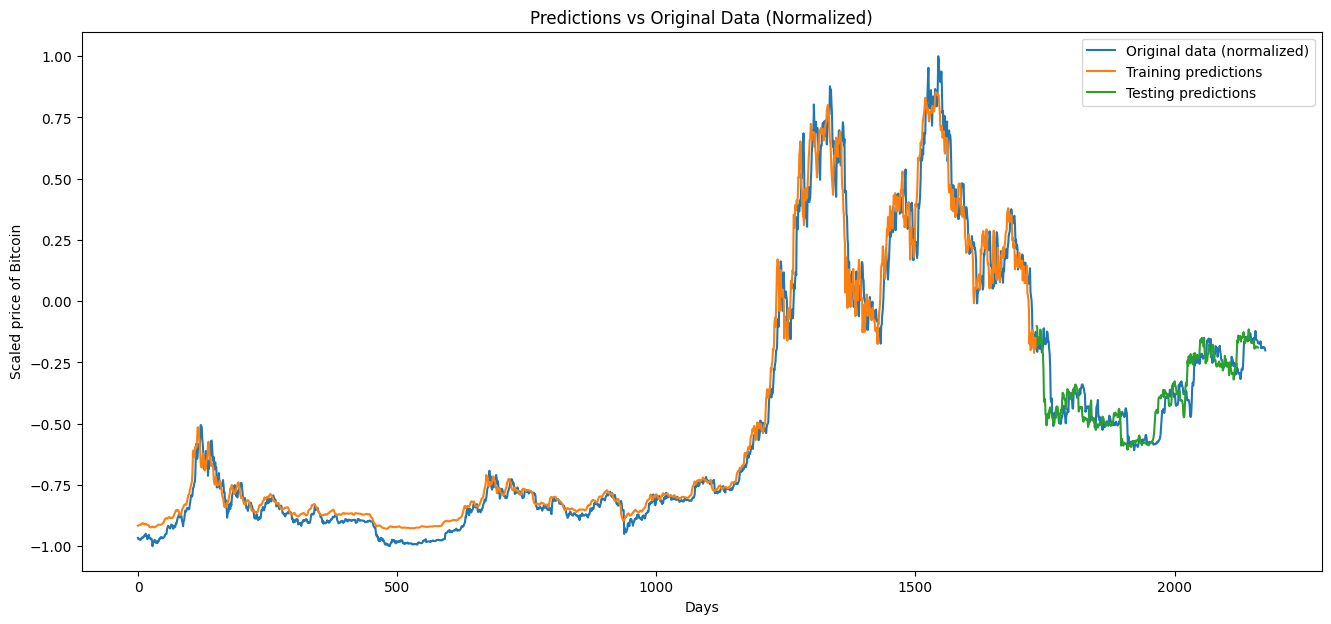

In [ ]:
# PLOT RESULTADOS NORMALIZADOS
plt.figure(figsize=(16,7))
plt.plot(data_to_use_normalized, label='Original data (normalized)')
plt.plot(train_results, label='Training predictions')
plt.plot(test_results, label='Testing predictions')
plt.title('Predictions vs Original Data (Normalized)')
plt.xlabel('Days')
plt.ylabel('Scaled price of Bitcoin')
plt.legend()
plt.show()

In [ ]:
# AJUSTE DOS RESULTADOS PARA PLOTAR (valores reais):
# Total de amostras: treino + teste
total_length = len(train_predictions_real + test_predictions_real)

# Lista final de resultados contínuos (None onde não há previsão)
train_results_real = []
test_results_real = []
for i in range(total_length):
    if i < len(train_predictions_real):
        train_results_real.append(train_predictions_real[i])
        test_results_real.append(None)
    else:
      train_results_real.append(None)
      test_index = i - len(train_predictions_real)
      test_results_real.append(test_predictions_real[test_index])

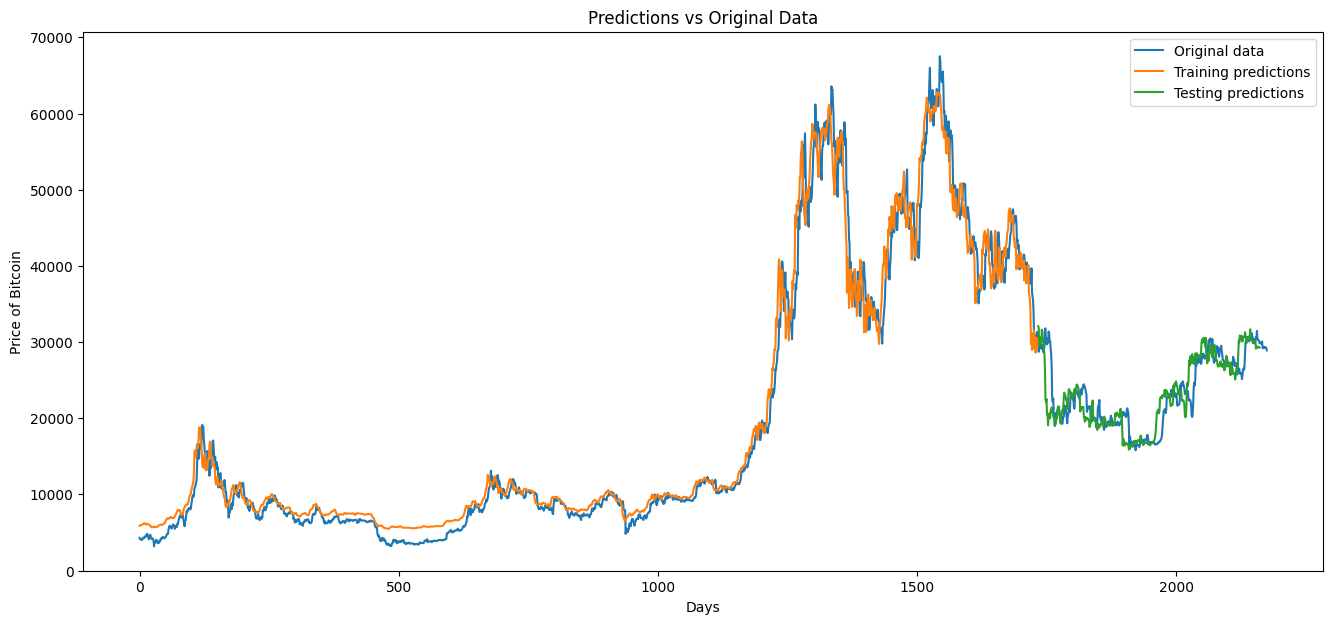

In [ ]:
# PLOT RESULTADOS REAIS:
plt.figure(figsize=(16,7))
plt.plot(data_to_use, label='Original data')
plt.plot(train_results_real, label='Training predictions')
plt.plot(test_results_real, label='Testing predictions')
plt.title('Predictions vs Original Data')
plt.xlabel('Days')
plt.ylabel('Price of Bitcoin')
plt.legend()
plt.show()

In [ ]:
target_values = y_test.flatten().tolist()
predicted_values = test_predictions_list

In [ ]:
# Exemplo: y_test_original e y_pred_original já revertidos do scaler
mse = mean_squared_error(target_values, predicted_values)
rmse = np.sqrt(mse)
mae = mean_absolute_error(target_values, predicted_values)
r2 = r2_score(target_values, predicted_values)

def pocid(y_true, y_pred):
    correct_dir = np.sum(np.sign(np.diff(y_true)) == np.sign(np.diff(y_pred)))
    total = len(y_true) - 1t
    return 100 * correct_dir / total

pocid_val = pocid(target_values, predicted_values)

print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R²: {r2:.4f}")
print(f"POCID: {pocid_val:.2f}%")


MSE: 0.0004
RMSE: 0.0207
MAE: 0.0137
R²: 0.9781
POCID: 47.78%
